# Лабораторная работа №1

### Кластерный анализ

**Цель работы:** разбить города мира на группы со схожими экономическими условиями, обосновать число групп, сравнить несколько методов кластеризации (K-Means, иерархическая кластеризация, DBSCAN) и дать содержательную интерпретацию полученных групп.

**Данные:** 48 городов, данные собраны банком Union Bank of Switzerland в 1991 году. Признаки:
> Work - взвешенное среднее число рабочих часов в год, посчитанное по 12 профессиям;
> Price - индекс цен на 112 товаров и услуг, включая аренду жилья (Цюрих = 100);
> Salary - индекс зарплаты за час работы после налогов и вычетов, посчитанный по 12 профессиям (Цюрих = 100).

**План работы:**
- загрузка данных и проверка на ошибки и пропуски;
- разведочный анализ и стандартизация признаков;
- метод главных компонент (PCA) и факторный анализ: какие скрытые факторы стоят за признаками;
- K-Means: выбор числа кластеров по нескольким критериям;
- иерархическая кластеризация (метод Уорда) как проверка выбора;
- DBSCAN: подбор параметров `eps` и `min_samples`, разбор шумовых объектов;
- сравнение методов, интерпретация кластеров, выводы.

In [1]:
# Подключаем библиотеки
import numpy as np                    # работа с массивами
import pandas as pd                   # работа с таблицами
import matplotlib.pyplot as plt       # графики
import seaborn as sns                 # тепловые карты

# Иерархическая кластеризация и дендрограмма
from scipy.cluster.hierarchy import linkage, dendrogram

# Стандартизация, понижение размерности, методы кластеризации
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors

# Метрики качества кластеризации
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score

sns.set_theme(style="whitegrid")

# Фиксируем случайность, чтобы при каждом запуске получались одинаковые результаты
RANDOM_STATE = 42

# Признаки, по которым будем кластеризовать города
FEATURES = ["Work", "Price", "Salary"]

## 1. Загрузка и проверка данных

В файле разделитель столбцов является точка с запятой, а дробная часть числа отделяется запятой. Поэтому при чтении указываем **sep=";"** и **decimal=","**.

In [2]:
raw = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")

print("Размер таблицы:", raw.shape)
display(raw.head())

display(raw.describe().round(1))

Размер таблицы: (48, 4)


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


,Work,Price,Salary
count,48.0,48.0,48.0
mean,1385.0,68.9,-378.7
std,2404.9,21.8,2027.3
min,-9999.0,30.3,-9999.0
25%,1740.8,49.6,12.2
50%,1834.5,70.5,40.3
75%,1972.8,81.7,58.7
max,2375.0,115.5,100.0


В таблице 48 городов и 4 столбца. Минимум `Work` и `Salary` равен -9999, а среднее `Salary` отрицательное. Такого быть не может: число часов и зарплата не бывают отрицательными. Значит, -9999 - это условный код пропуска. Посмотрим, у каких городов он встречается.

In [3]:
# Выбираем строки, где хотя бы в одном признаке стоит код пропуска -9999
bad_rows = raw[(raw["Work"] == -9999) | (raw["Salary"] == -9999)]
display(bad_rows)

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


Пропуски есть у двух городов - Cairo и Jakarta, причём сразу в двух признаках из трёх (`Work` и `Salary`). Восстановить два признака по одному ненадёжно. Заменять их средним тоже плохо. Обычно такие города искусственно попали бы в центр данных и исказили бы группы. Поэтому удаляем эти 2 города, остаётся 46.

In [4]:
def clean_data(data, missing_code):
    # data - исходная таблица
    # missing_code - число, которым в файле обозначен пропуск (у нас -9999)

    # Заменяем код пропуска на NaN - стандартное обозначение пропуска в pandas
    data = data.replace(missing_code, np.nan)

    # Удаляем строки, в которых есть хотя бы один пропуск
    data = data.dropna()

    # Перенумеровываем строки заново: 0, 1, 2, ...
    data = data.reset_index(drop=True)
    return data

df = clean_data(raw, missing_code=-9999)
print("Осталось городов:", len(df))
display(df.describe().round(1))

Осталось городов: 46


,Work,Price,Salary
count,46.0,46.0,46.0
mean,1879.9,70.1,39.5
std,174.3,21.4,24.8
min,1583.0,30.3,2.7
25%,1745.2,51.8,14.4
50%,1849.0,70.9,43.6
75%,1976.2,81.9,59.7
max,2375.0,115.5,100.0


После очистки отрицательных значений больше нет: `Work` меняется от 1583 до 2375 часов в год, `Price` - от 30,3 до 115,5, `Salary` - от 2,7 до 100.

## 2. Разведочный анализ и стандартизация

Посмотрим, как распределены признаки и как они связаны между собой. Это поможет заранее понять, какие группы городов можно ожидать.

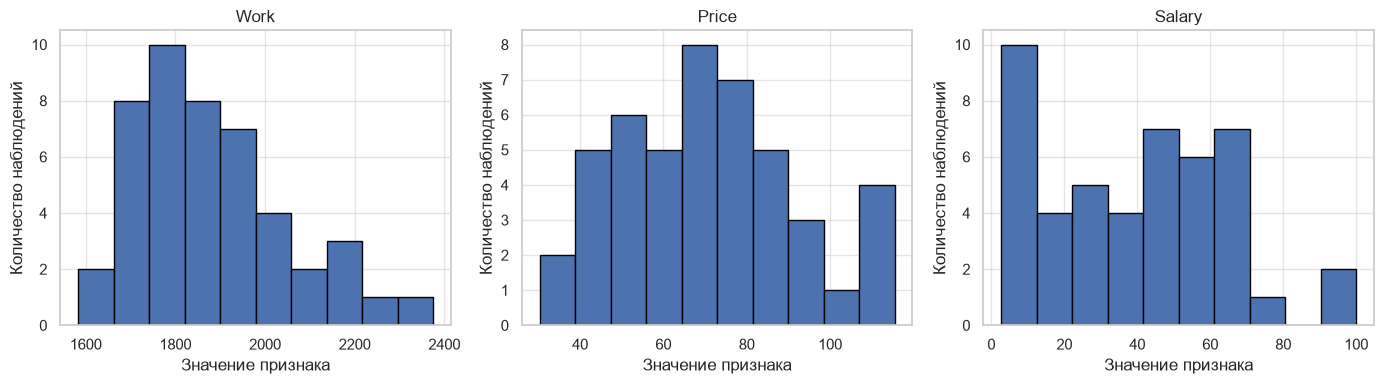

In [22]:
# Гистограммы трёх признаков: сколько городов попадает в каждый интервал значений
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i in range(3):
    col = FEATURES[i]
    axes[i].hist(df[col], bins=10, edgecolor="black")
    axes[i].set_title(col)
    axes[i].set_xlabel("Значение признака")
    axes[i].set_ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()

На гистограммах видно, что распределение `Work` смещено влево: в большинстве городов работают 1650-2000 часов в год, и лишь несколько городов работают заметно больше (до 2375 часов у Hong Kong). `Price` распределена довольно равномерно, от 30 до 115. У `Salary` около 10 городов имеют очень низкую зарплату (до 12), а два города заметно выше остальных (Zurich и Geneva, 100 и 90). Значит, в данных уже видны города с низкими и с высокими доходами, а также небольшая группа городов с очень длинным рабочим годом.

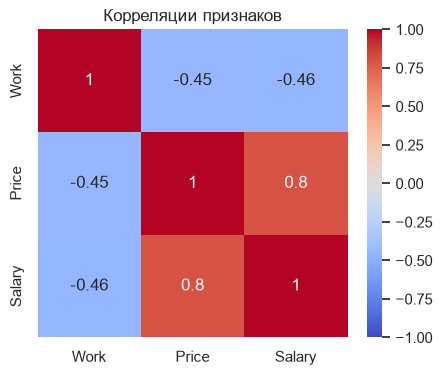

In [6]:
# Матрица корреляций: насколько сильно признаки связаны друг с другом (от -1 до 1)
plt.figure(figsize=(5, 4))
sns.heatmap(df[FEATURES].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции признаков")
plt.show()

`Price` и `Salary` сильно связаны (корреляция 0,80): где высокие цены, там и высокие зарплаты. `Work` связана с ними отрицательно (-0,45 и -0,46): где зарабатывают больше, там работают меньше часов.

Признаки измерены в разных единицах: `Work` - тысячи часов, `Price` и `Salary` - индексы до 115. Все методы кластеризации в работе опираются на расстояния между городами, поэтому без приведения к одному масштабу `Work` полностью определял бы результат. Поэтому стандартизируем признаки: из каждого вычитаем среднее и делим на стандартное отклонение. После этого у всех признаков среднее 0 и стандартное отклонение 1

In [7]:
# Стандартизация: (значение - среднее) / стандартное отклонение
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])

# Проверяем: средние должны стать 0, стандартные отклонения - 1
print("Средние после стандартизации:", X.mean(axis=0).round(2))
print("Стандартные отклонения:", X.std(axis=0).round(2))

Средние после стандартизации: [ 0. -0.  0.]
Стандартные отклонения: [1. 1. 1.]


## 3. Метод главных компонент (PCA) и факторный анализ

Признаков всего три, поэтому для самой кластеризации сокращать их число не нужно. PCA и факторный анализ используем для двух целей:
- понять, какие скрытые факторы стоят за тремя признаками;
- получить двумерную картинку (плоскость двух главных компонент), на которой удобно показывать кластеры.

In [8]:
# PCA: ищем новые оси (главные компоненты), вдоль которых данные сильнее всего меняются
pca = PCA()
pca.fit(X)

# Какую долю общего разброса данных объясняет каждая компонента
print("Доля дисперсии по компонентам:", pca.explained_variance_ratio_.round(3))
print("Накопленная доля:", pca.explained_variance_ratio_.cumsum().round(3))

# Нагрузки: с каким весом каждый признак входит в каждую компоненту
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
print("\nНагрузки PCA:")
display(loadings.round(2))

# Факторный анализ с 2 факторами; вращение varimax упрощает интерпретацию факторов
fa = FactorAnalysis(n_components=2, rotation="varimax", random_state=RANDOM_STATE)
fa.fit(X)

fa_loadings = pd.DataFrame(fa.components_.T, index=FEATURES, columns=["F1", "F2"])
print("Нагрузки факторов:")
display(fa_loadings.round(2))

Доля дисперсии по компонентам: [0.72  0.215 0.065]
Накопленная доля: [0.72  0.935 1.   ]

Нагрузки PCA:


,PC1,PC2,PC3
Work,-0.48,0.87,0.01
Price,0.62,0.35,-0.71
Salary,0.62,0.34,0.71


Нагрузки факторов:


,F1,F2
Work,-0.45,0.33
Price,0.88,-0.16
Salary,0.88,-0.18


Первая компонента PC1 объясняет 72% разброса. В неё `Price` и `Salary` входят с одинаковым весом 0,62, а `Work` - с обратным знаком (-0,48). Значит, PC1 - это уровень цен и зарплат: справа богатые и дорогие города, слева бедные.

Вторая компонента PC2 объясняет ещё 21,5%, и главный вклад в неё вносит `Work` (0,87). Значит, PC2 - это в основном рабочее время.

Две компоненты вместе объясняют 93,5% разброса, поэтому плоскость PC1-PC2 почти без потерь показывает расположение городов.

Факторный анализ даёт ту же картину: в первый фактор `Price` и `Salary` входят с весом 0,88, а `Work` - с весом -0,45. Второй фактор слабее. При трёх признаках возможности факторного анализа ограничены, поэтому дальше опираемся на PCA.

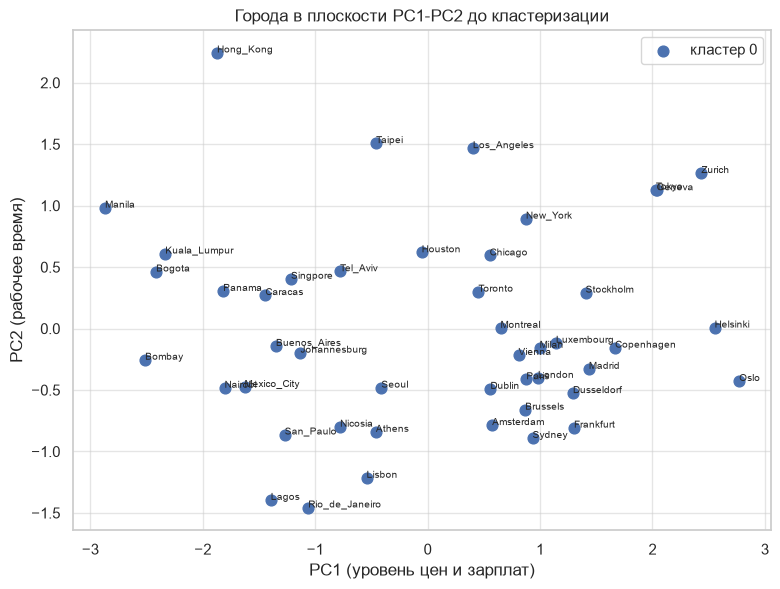

In [9]:
# Координаты городов в плоскости двух главных компонент - только для графиков
pca2 = PCA(n_components=2)
X2 = pca2.fit_transform(X)


def plot_clusters(labels, title):
    # labels - номер кластера для каждого города (-1 означает шум в DBSCAN)
    # title - заголовок графика
    fig, ax = plt.subplots(figsize=(9, 6.5))

    # Рисуем каждый кластер своим цветом, шум - чёрными крестиками
    for lab in sorted(set(labels)):
        mask = labels == lab
        if lab == -1:
            ax.scatter(X2[mask, 0], X2[mask, 1], c="black", marker="x", s=60, label="шум")
        else:
            ax.scatter(X2[mask, 0], X2[mask, 1], s=60, label="кластер " + str(lab))

    # Подписываем название каждого города рядом с его точкой
    for i in range(len(df)):
        ax.annotate(df["City"][i], (X2[i, 0], X2[i, 1]), fontsize=7)

    ax.set_xlabel("PC1 (уровень цен и зарплат)")
    ax.set_ylabel("PC2 (рабочее время)")
    ax.set_title(title)
    ax.legend()
    plt.show()


# Пока кластеров нет: все города одного цвета (метка 0)
plot_clusters(np.zeros(len(df), dtype=int), "Города в плоскости PC1-PC2 до кластеризации")


На графике видно, что города не разбиваются на чётко отделённые облака. Справа расположены богатые города Европы, Северной Америки и Япония, слева - бедные города. Сверху слева выделяются города с очень длинным рабочим годом (Hong Kong, Manila, Taipei). Значит, группы есть, но границы между ними размыты, и число кластеров нужно выбирать по критериям.

## 4. K-Means: выбор числа кластеров

K-Means делит города на заданное число кластеров k так, чтобы города внутри кластера были близки к центру своего кластера. Число k нужно задать заранее, поэтому переберём k от 2 до 8 и сравним четыре критерия:
- Inertia (метод локтя) - сумма квадратов расстояний от городов до центров их кластеров. С ростом k она всегда убывает, ищем точку, после которой убывание резко замедляется;
- Silhouette (силуэт) - насколько город ближе к своему кластеру, чем к соседнему, от -1 до 1. Чем больше, тем лучше;
- Calinski-Harabasz - отношение разброса между кластерами к разбросу внутри кластеров. Чем больше, тем лучше;
- Davies-Bouldin - насколько кластеры похожи на ближайших соседей. Чем меньше, тем лучше.

Параметры функции:
- `k_values` - какие значения k перебирать. Берём от 2 до 8: при 46 городах больше 8 кластеров дало бы группы из нескольких городов;
- `n_init` - сколько раз запускать K-Means со случайными начальными центрами (выбирается лучший запуск). Берём 50: данных мало, запуски быстрые, а результат получается устойчивым;
- `random_state` - фиксирует случайность для воспроизводимости.

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,61.117,0.470,55.351,0.808
3,47.361,0.388,41.146,0.905
4,35.553,0.366,40.342,1.063
5,27.763,0.375,40.699,0.907
6,23.213,0.373,39.560,0.933
7,18.701,0.397,41.466,0.823
8,15.309,0.396,43.506,0.786


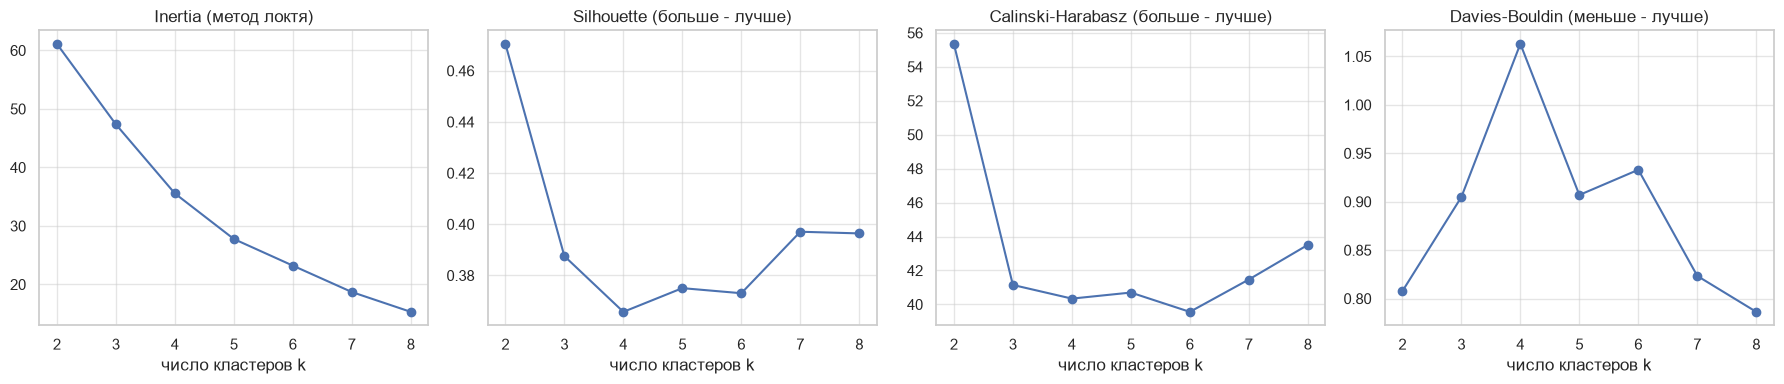

In [10]:
def evaluate_k(X, k_values, n_init, random_state):
    # Для каждого k обучаем K-Means и считаем 4 критерия качества
    rows = []
    for k in k_values:
        km = KMeans(n_clusters=k, n_init=n_init, random_state=random_state)
        labels = km.fit_predict(X)
        rows.append({
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels),
            "davies_bouldin": davies_bouldin_score(X, labels)
        })
    return pd.DataFrame(rows).set_index("k")


metrics = evaluate_k(X, k_values=range(2, 9), n_init=50, random_state=RANDOM_STATE)
display(metrics.round(3))

# Рисуем 4 графика: по одному на каждый критерий
columns = ["inertia", "silhouette", "calinski_harabasz", "davies_bouldin"]
titles = ["Inertia (метод локтя)", "Silhouette (больше - лучше)",
          "Calinski-Harabasz (больше - лучше)", "Davies-Bouldin (меньше - лучше)"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i in range(4):
    axes[i].plot(metrics.index, metrics[columns[i]], "o-")
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("число кластеров k")
plt.tight_layout()
plt.show()

**Обоснование выбора k.**
- Silhouette наибольший при k = 2 (0,47), при k = 3 и больше он держится около 0,37-0,40.
- Calinski-Harabasz тоже наибольший при k = 2 (55), а при k = 3...7 держится около 40-41.
- Davies-Bouldin при k = 2 равен 0,81. Меньшее значение получается только при k = 8 (0,79), но это уже деление 46 городов на мелкие группы.
- Локоть выражен слабо: inertia убывает плавно (61 → 47 → 36 → 28 → 23), заметно медленнее она убывает только после k = 4.

Получается, что по метрикам самое чёткое разбиение - k = 2 («богатые» и «остальные»), а k = 3 и k = 4 по метрикам примерно равноценны.

Но при k = 2 теряется важная особенность данных. PCA показал, что рабочее время - отдельная ось (21,5% разброса). При k = 3 небогатые города делятся на две группы с почти одинаковыми ценами и зарплатами, но с разным рабочим временем. Поэтому выбираем k = 3 - наименьшее k, которое учитывает обе оси. Платой за это служит невысокий силуэт (0,39): группы есть, но границы между ними размыты. Устойчивость выбора проверим в конце работы на k = 2 и k = 4.

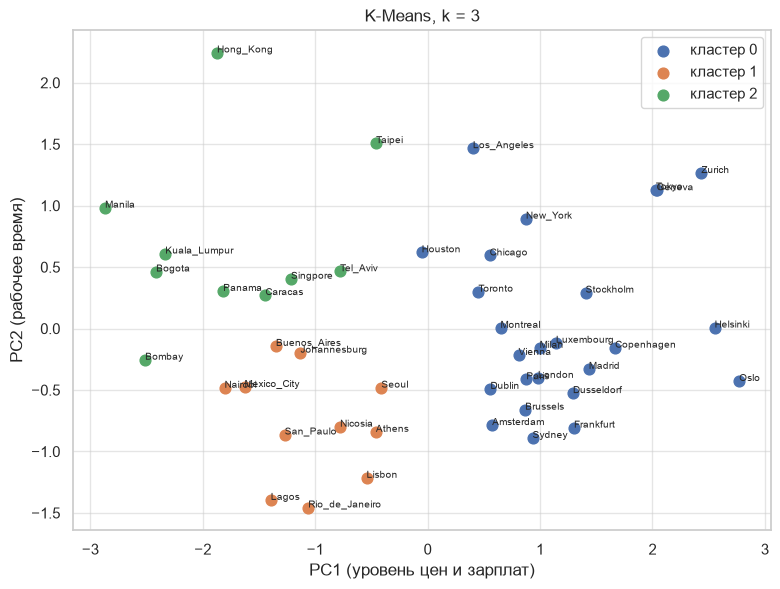

In [11]:
def fit_kmeans(X, k, n_init, random_state):
    # Обучаем K-Means и получаем номер кластера для каждого города
    km = KMeans(n_clusters=k, n_init=n_init, random_state=random_state)
    labels = km.fit_predict(X)

    # K-Means нумерует кластеры в случайном порядке.
    # Перенумеруем их по возрастанию среднего Work:
    # кластер 0 - меньше всего рабочих часов, последний - больше всего.
    work_mean = df.groupby(labels)["Work"].mean()
    new_number = work_mean.rank().astype(int) - 1
    return new_number.loc[labels].values


K = 3
df["km"] = fit_kmeans(X, k=K, n_init=50, random_state=RANDOM_STATE)
plot_clusters(df["km"].values, "K-Means, k = 3")

На графике кластеры расположены так:
- кластер 0 (синий) - справа, это богатые города;
- кластер 1 (оранжевый) - слева внизу, это небогатые города с обычным рабочим временем;
- кластер 2 (зелёный) - слева вверху, это небогатые города с длинным рабочим годом.

Значит, K-Means разделил города именно по двум осям, найденным с помощью PCA. Проверим, насколько уверенно каждый город попал в свой кластер.

Средний силуэт: 0.388


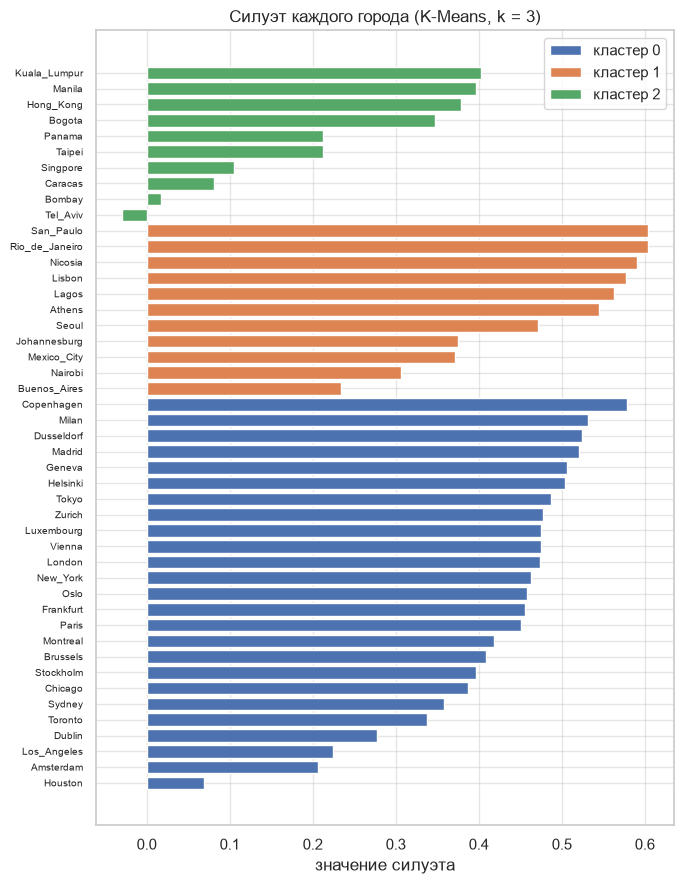

Пограничные города (силуэт < 0.1): ['Bombay', 'Caracas', 'Houston', 'Tel_Aviv']


In [12]:
# Силуэт для каждого города отдельно:
# близко к 1 - город уверенно в своём кластере, около 0 - на границе двух кластеров
df["silhouette"] = silhouette_samples(X, df["km"])
print("Средний силуэт:", round(df["silhouette"].mean(), 3))

# Сортируем города по кластеру и по силуэту, чтобы столбики шли группами
sil_sorted = df.sort_values(["km", "silhouette"])
colors = ["C0", "C1", "C2"]

plt.figure(figsize=(7, 9))
for lab in range(K):
    part = sil_sorted[sil_sorted["km"] == lab]
    plt.barh(part["City"], part["silhouette"], color=colors[lab], label="кластер " + str(lab))
plt.title("Силуэт каждого города (K-Means, k = 3)")
plt.xlabel("значение силуэта")
plt.yticks(fontsize=7)
plt.legend()
plt.tight_layout()
plt.show()

# Пограничные города: силуэт меньше 0.1
border = df[df["silhouette"] < 0.1]
print("Пограничные города (силуэт < 0.1):", list(border["City"]))

Средний силуэт равен 0,388, и у большинства городов он положительный, т.е. города в основном попали в подходящий кластер. Пограничных городов четыре: Bombay, Caracas, Houston и Tel_Aviv. На графике PCA они лежат между кластерами, поэтому их отнесение к группе нужно трактовать осторожно.

## 5. Иерархическая кластеризация (метод Уорда)

Иерархическая кластеризация сначала считает каждый город отдельным кластером, а затем на каждом шаге объединяет два самых близких кластера. Метод Уорда объединяет те кластеры, при слиянии которых меньше всего растёт разброс внутри кластера. Это та же идея, что и у K-Means, поэтому методы можно сравнивать.

Результат показывают на дендрограмме: высота слияния показывает, насколько непохожие кластеры объединились. Большой скачок высоты означает, что объединились сильно различающиеся группы, и разрезать дерево стоит перед ним.

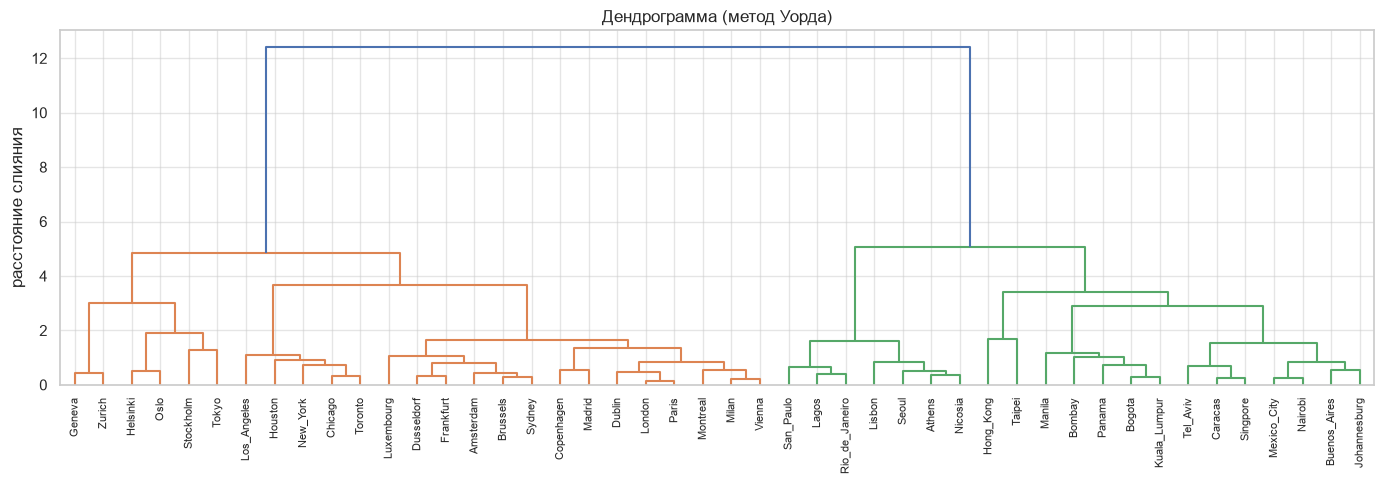

Последние 6 расстояний слияния: [ 2.99  3.4   3.66  4.86  5.06 12.4 ]


In [13]:
# Строим дерево объединений методом Уорда
Z = linkage(X, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, labels=df["City"].values, leaf_rotation=90, leaf_font_size=8)
plt.title("Дендрограмма (метод Уорда)")
plt.ylabel("расстояние слияния")
plt.tight_layout()
plt.show()

# Высоты 6 последних слияний (последнее - объединение двух последних кластеров в один)
print("Последние 6 расстояний слияния:", Z[-6:, 2].round(2))

Последние слияния происходят на высотах 2,99; 3,40; 3,66; 4,86; 5,06; 12,40. Резкий скачок (с 5,06 до 12,40) есть только при последнем слиянии, когда из двух кластеров получается один. Значит, дендрограмма, как и силуэт, сильнее всего выделяет 2 крупные группы. Переходы от 4 кластеров к 3 и от 3 к 2 происходят на близких высотах (4,86 и 5,06), т.е. дендрограмма не даёт чёткого выбора между k = 3 и k = 4. Выбор k = 3 основан на содержательных причинах, описанных выше. Сравним разбиения Уорда и K-Means при k = 3.

In [14]:
# Разбиение методом Уорда на 3 кластера
ward = AgglomerativeClustering(n_clusters=K, linkage="ward")
df["ward"] = ward.fit_predict(X)

# ARI (скорректированный индекс Рэнда) - насколько совпадают два разбиения:
# 1 - полностью совпадают, около 0 - совпадение не лучше случайного
print("ARI (K-Means и Ward, k = 3):", round(adjusted_rand_score(df["km"], df["ward"]), 2))

ARI (K-Means и Ward, k = 3): 0.86


ARI = 0,86, т.е. разбиения K-Means и Уорда почти совпадают. Значит, кластеры при k = 3 не случайный результат одного метода, а устойчивая структура данных.

## 6. DBSCAN

DBSCAN не требует заранее задавать число кластеров. Он объединяет в кластер города, расположенные плотно друг к другу, а изолированные города помечает как шум (метка -1). У метода два параметра:
- `eps` - радиус окрестности города;
- `min_samples` - сколько городов (включая сам город) должно быть в его окрестности, чтобы он считался «ядром» кластера.

Выбор `min_samples`. Обычно берут `min_samples` не меньше чем число признаков + 1, т.е. 3 + 1 = 4. Берём 4: при меньшем значении появляются мелкие кластеры из 2-3 городов, а при большем при всего 46 городах слишком много городов уходит в шум.

Выбор `eps` делаем по графику k-расстояний: для каждого города находим расстояние до `min_samples`-го ближайшего соседа (сам город считается первым), сортируем эти расстояния и ищем «колено» - место, где кривая резко идёт вверх. Города выше колена изолированы и станут шумом.

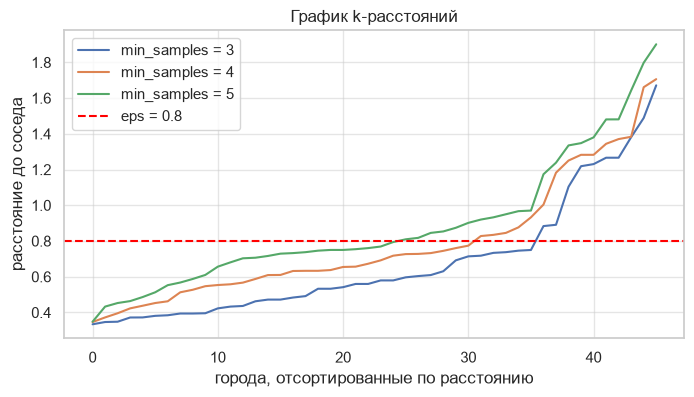

Городов с расстоянием не больше 0.9: 35 из 46
Наибольшие расстояния: [1.34 1.37 1.38 1.66 1.71]


In [15]:
def k_distances(X, min_samples):
    # Для каждого города ищем min_samples ближайших соседей (первый - сам город)
    nn = NearestNeighbors(n_neighbors=min_samples)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)

    # Берём расстояние до последнего (самого дальнего из найденных) соседа и сортируем
    return np.sort(distances[:, -1])


MIN_SAMPLES = 4

plt.figure(figsize=(8, 4))
for ms in [3, 4, 5]:
    plt.plot(k_distances(X, ms), label="min_samples = " + str(ms))
plt.axhline(0.8, color="red", linestyle="--", label="eps = 0.8")
plt.xlabel("города, отсортированные по расстоянию")
plt.ylabel("расстояние до соседа")
plt.title("График k-расстояний")
plt.legend()
plt.show()

d4 = k_distances(X, MIN_SAMPLES)
print("Городов с расстоянием не больше 0.9:", (d4 <= 0.9).sum(), "из", len(d4))
print("Наибольшие расстояния:", d4[-5:].round(2))

При `min_samples = 4` у 35 городов из 46 расстояние до соседа не больше 0,9, дальше кривая резко поднимается (до 1,71). Значит, колено находится примерно в районе 0,8-0,9, а города выше него изолированы. Чтобы выбрать точное значение, переберём сетку параметров. Для каждой пары считаем число кластеров, число шумовых городов и силуэт (только по городам, не попавшим в шум).

In [16]:
def dbscan_grid(X, eps_values, ms_values):
    # Перебираем все пары (min_samples, eps) и запоминаем результат DBSCAN
    rows = []
    for ms in ms_values:
        for eps in eps_values:
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)

            not_noise = labels != -1                    # города, не попавшие в шум
            n_clusters = len(set(labels[not_noise]))    # число найденных кластеров

            # Силуэт можно посчитать, только если кластеров хотя бы 2
            if n_clusters > 1:
                sil = silhouette_score(X[not_noise], labels[not_noise])
            else:
                sil = np.nan

            rows.append({
                "min_samples": ms,
                "eps": eps,
                "кластеров": n_clusters,
                "шум": (labels == -1).sum(),
                "силуэт без шума": round(sil, 3)
            })
    return pd.DataFrame(rows)


grid = dbscan_grid(X, eps_values=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0], ms_values=[3, 4, 5])
display(grid)

,min_samples,eps,кластеров,шум,силуэт без шума
0,3,0.5,3,23,0.489
1,3,0.6,2,16,0.554
2,3,0.7,2,11,0.540
3,3,0.8,2,8,0.512
4,3,0.9,1,8,NaN
5,3,1.0,1,8,NaN
6,4,0.5,1,35,NaN
7,4,0.6,3,21,0.477
8,4,0.7,3,11,0.356
9,4,0.8,2,8,0.512


**Выбор параметров.** При `min_samples = 4`:
- `eps = 0,5` и `0,6` - слишком маленький радиус: в шум уходят 35 и 21 город из 46;
- `eps = 0,7` - 3 кластера и 11 шумовых городов: от небогатых городов отделяется маленькая группа из 4 городов (Athens, Lisbon, Nicosia, Seoul), в шум попадают даже обычные города (Houston, Los Angeles), а силуэт ниже (0,356);
- `eps = 0,8` - 2 кластера, 8 шумовых городов и наибольший силуэт 0,512;
- `eps = 0,9` и больше - кластеры сливаются в один.

Выбираем `eps = 0,8`. Это значение лежит у нижнего края колена на графике k-расстояний и является наибольшим, при котором ещё различаются два кластера. Результат устойчив к выбору `min_samples`: при `min_samples = 3` и `5` с `eps = 0,8` тоже получаются 2 кластера и 8-9 шумовых городов.

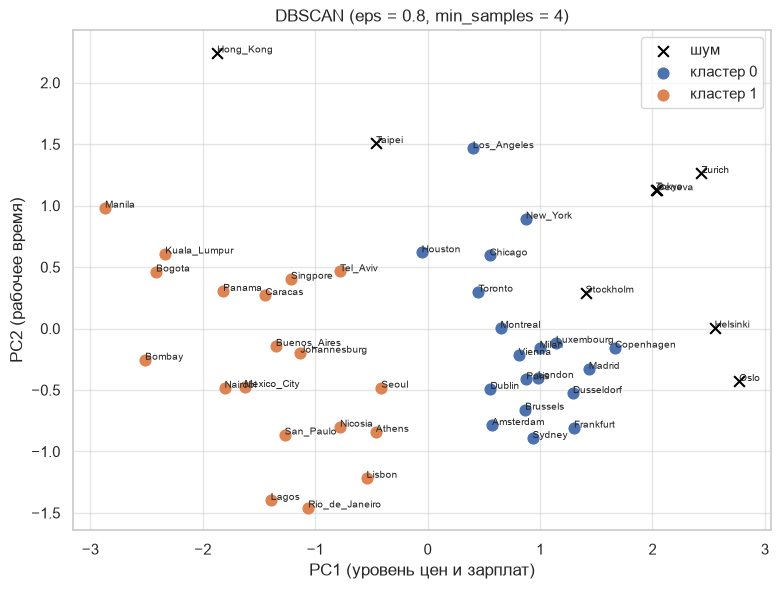

Шум (8): Geneva, Helsinki, Hong_Kong, Oslo, Stockholm, Taipei, Tokyo, Zurich
Кластер 0 (19): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna
Кластер 1 (19): Athens, Bogota, Bombay, Buenos_Aires, Caracas, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Tel_Aviv


In [17]:
EPS = 0.8

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
df["db"] = db.fit_predict(X)

plot_clusters(df["db"].values, "DBSCAN (eps = 0.8, min_samples = 4)")

# Выводим состав каждого кластера и шума
for lab in sorted(df["db"].unique()):
    cities = df[df["db"] == lab]["City"]
    if lab == -1:
        print("Шум (" + str(len(cities)) + "):", ", ".join(cities))
    else:
        print("Кластер " + str(lab) + " (" + str(len(cities)) + "):", ", ".join(cities))

DBSCAN нашёл 2 кластера по 19 городов и 8 шумовых городов. Кластер 0 - богатые города Европы, Северной Америки и Австралии, кластер 1 - небогатые города Азии, Латинской Америки, Африки и юга Европы. Шумовые города на графике лежат на краях: справа вверху самые богатые города, слева вверху Hong Kong и Taipei.

### Разбор объектов, отнесённых к шуму

Чтобы понять, чем шумовые города отличаются от остальных, сравним их признаки со средними по кластерам. Для наглядности добавим показатель покупательной способности `Purchasing = Salary / Price * 100` - сколько товаров можно купить на час работы (Цюрих = 100). В кластеризации он не участвует

In [18]:
# Покупательная способность: зарплата относительно цен
df["Purchasing"] = df["Salary"] / df["Price"] * 100

cols = ["Work", "Price", "Salary", "Purchasing"]

# Шумовые города, отсортированные по убыванию цен
noise = df[df["db"] == -1].sort_values("Price", ascending=False)
display(noise[["City"] + cols].round(1))

# Средние значения по двум кластерам DBSCAN для сравнения
print("Средние по кластерам DBSCAN (без шума):")
display(df[df["db"] != -1].groupby("db")[cols].mean().round(1))

,City,Work,Price,Salary,Purchasing
31,Oslo,1583.0,115.5,63.7,55.2
42,Tokyo,1880.0,115.0,68.0,59.1
13,Helsinki,1667.0,113.6,66.6,58.6
38,Stockholm,1805.0,111.3,39.2,35.2
45,Zurich,1868.0,100.0,100.0,100.0
12,Geneva,1880.0,95.9,90.3,94.2
40,Taipei,2145.0,84.3,34.5,40.9
14,Hong_Kong,2375.0,63.8,27.8,43.6


Средние по кластерам DBSCAN (без шума):


,Work,Price,Salary,Purchasing
db,,,,
0,1792.0,77.5,55.2,71.7
1,1959.2,50.1,14.8,28.5


Шумовые города - это не ошибки в данных, а города с нетипичным сочетанием условий. Они делятся на две группы:
- Самые дорогие и богатые - Oslo, Tokyo, Helsinki, Stockholm, Zurich, Geneva. У них самые высокие цены (от 95,9 до 115,5 при среднем 77,5 в богатом кластере). У Zurich и Geneva ещё и самые высокие зарплаты (100 и 90,3). Рядом с ними мало похожих городов, поэтому DBSCAN не включает их в богатый кластер.
- «Трудоголики» - Hong Kong и Taipei. Очень длинный рабочий год (2375 и 2145 часов, у Hong Kong - максимум в выборке) при зарплате выше, чем в небогатом кластере (27,8 и 34,5 против 14,8), а у Taipei ещё и высокие цены (84,3). Ни в богатый, ни в небогатый кластер они не вписываются.

Значит, DBSCAN в отличие от K-Means выделяет крайние города отдельно, а не присоединяет их к ближайшему кластеру.

## 7. Сравнение методов и интерпретация кластеров

In [19]:
# Попарное сравнение трёх разбиений через ARI
# (для DBSCAN шум считается отдельной группой с меткой -1)
print("K-Means и Ward:  ", round(adjusted_rand_score(df["km"], df["ward"]), 2))
print("K-Means и DBSCAN:", round(adjusted_rand_score(df["km"], df["db"]), 2))
print("Ward и DBSCAN:   ", round(adjusted_rand_score(df["ward"], df["db"]), 2))

K-Means и Ward:   0.86
K-Means и DBSCAN: 0.52
Ward и DBSCAN:    0.52


K-Means и Уорд почти совпадают (ARI = 0,86). С DBSCAN совпадение меньше (0,52), т.к. DBSCAN выделяет 8 шумовых городов и не делит небогатые города по рабочему времени. Для итоговой интерпретации берём K-Means с k = 3. Посмотрим на средние значения признаков в каждом кластере.

,n,Work,Price,Salary,Purchasing
km,,,,,
0,25,1789.2,85.0,59.0,70.6
1,11,1855.5,50.8,16.6,31.8
2,10,2133.5,54.2,16.1,27.6


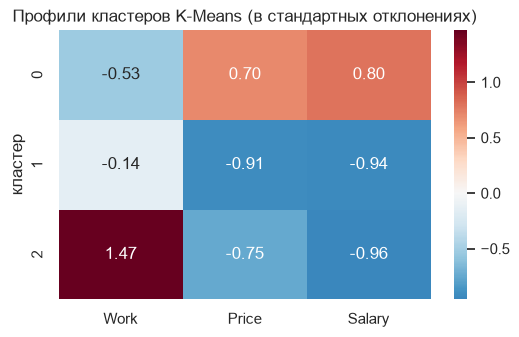

Кластер 0 (25): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 1 (11): Athens, Buenos_Aires, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul
Кластер 2 (10): Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv


In [20]:
def cluster_profile(data, label_col, cols):
    # data - таблица, label_col - столбец с номерами кластеров, cols - признаки
    # Считаем средние признаков по кластерам и добавляем размер кластера n
    profile = data.groupby(label_col)[cols].mean().round(1)
    profile.insert(0, "n", data.groupby(label_col).size())
    return profile


display(cluster_profile(df, "km", cols))

# Те же средние, но в стандартизированных единицах:
# 0 - средний уровень по всем городам, +1 - на одно стандартное отклонение выше среднего
z_profile = pd.DataFrame(X, columns=FEATURES).groupby(df["km"]).mean()

plt.figure(figsize=(6, 3.5))
sns.heatmap(z_profile, annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Профили кластеров K-Means (в стандартных отклонениях)")
plt.ylabel("кластер")
plt.show()

# Состав кластеров
for lab in range(K):
    cities = df[df["km"] == lab]["City"]
    print("Кластер " + str(lab) + " (" + str(len(cities)) + "):", ", ".join(cities))

### Интерпретация кластеров K-Means (k = 3)

| Кластер | Профиль | Города |
|---|---|---|
| **0 - богатые развитые города** (25) | Самый короткий рабочий год (1789 часов), высокие цены (85,0) и зарплаты (59,0), самая высокая покупательная способность (70,6) | Западная Европа, Северная Америка, Sydney, Tokyo, Zurich, Geneva, скандинавские столицы |
| **1 - небогатые города с обычным рабочим временем** (11) | Рабочий год 1856 часов (близко к среднему), низкие цены (50,8) и зарплаты (16,6) | Athens, Lisbon, Nicosia, Seoul, Johannesburg, Nairobi, Lagos, Mexico City, Rio de Janeiro, San Paulo, Buenos Aires |
| **2 - небогатые города с длинным рабочим годом** (10) | Самый длинный рабочий год (2134 часа), низкие цены (54,2) и зарплаты (16,1) | Hong Kong, Taipei, Singapore, Manila, Bombay, Kuala Lumpur, Bogota, Caracas, Panama, Tel Aviv |

На тепловой карте видно, что кластер 0 выше среднего по ценам и зарплатам (+0,70 и +0,80) и ниже по рабочему времени (-0,53). Кластеры 1 и 2 почти одинаково ниже среднего по ценам и зарплатам (около -0,9), но сильно различаются по рабочему времени (-0,14 и +1,47).

Получается, что чем богаче город, тем меньше в нём работают. А небогатые города делятся на две группы именно по рабочему времени, поэтому k = 3 даёт больше информации, чем k = 2.

### Проверка устойчивости выбора k

In [21]:
# Смотрим, как меняются кластеры при соседних значениях k
for k in [2, 4]:
    df["tmp"] = fit_kmeans(X, k=k, n_init=50, random_state=RANDOM_STATE)
    print("k =", k, "| ARI с k = 3:", round(adjusted_rand_score(df["km"], df["tmp"]), 2))
    display(cluster_profile(df, "tmp", cols))

k = 2 | ARI с k = 3: 0.79


,n,Work,Price,Salary,Purchasing
tmp,,,,,
0,25,1789.2,85.0,59.0,70.6
1,21,1987.9,52.4,16.3,29.8


k = 4 | ARI с k = 3: 0.75


,n,Work,Price,Salary,Purchasing
tmp,,,,,
0,6,1780.5,108.6,71.3,67.0
1,19,1792.0,77.5,55.2,71.7
2,11,1855.5,50.8,16.6,31.8
3,10,2133.5,54.2,16.1,27.6


- При k = 2 богатый кластер (25 городов) остаётся прежним, а два небогатых кластера сливаются в один (21 город). Теряется различие по рабочему времени.
- При k = 4 три кластера из k = 3 сохраняются, а из богатых городов выделяется отдельная группа из 6 самых дорогих (средний индекс цен 108,6). Это те же города, которые DBSCAN отнёс к шуму: Zurich, Geneva, Oslo, Helsinki, Stockholm, Tokyo.

Значит, k = 4 не противоречит k = 3, а лишь подробнее делит богатые города. Структура «богатые / небогатые с обычным рабочим временем / небогатые с длинным рабочим годом» сохраняется.

## Выводы

Данные. В исходном файле пропуски были закодированы числом -9999 (Cairo и Jakarta, по два признака из трёх). Эти города удалены, анализ проведён по 46 городам. Признаки стандартизированы, т.к. они измерены в разных единицах, а все методы опираются на расстояния.

Структура признаков. PCA и факторный анализ показали, что за тремя признаками стоят два фактора: уровень цен и зарплат (PC1, 72% разброса) и рабочее время (PC2, 21,5%). Цены и зарплаты сильно связаны (корреляция 0,80), а рабочее время связано с ними отрицательно.

Число кластеров. По силуэту, индексу Calinski-Harabasz и дендрограмме сильнее всего выделяются 2 группы. Мы выбрали k = 3, т.к. только при k ≥ 3 учитывается вторая ось - рабочее время. Метод Уорда даёт почти то же разбиение (ARI = 0,86), значит, кластеры устойчивы. Силуэт 0,39 показывает, что границы между группами размыты.

Группы городов (K-Means, k = 3):
- богатые развитые города с коротким рабочим годом (25 городов);
- небогатые города с обычным рабочим временем (11 городов);
- небогатые города с длинным рабочим годом (10 городов).

DBSCAN (`min_samples = 4`, `eps = 0,8`, параметры выбраны по графику k-расстояний и перебору сетки) нашёл 2 кластера - богатые и небогатые города - и 8 шумовых городов. Шум - это города с нетипичными условиями: 6 самых дорогих и богатых (Zurich, Geneva, Oslo, Helsinki, Stockholm, Tokyo) и 2 «трудоголика» (Hong Kong, Taipei).